Ta can phan biet duoc 3 thu cho $3 cua paper 2308:
-camera
-gaussian
-rasterizer


In [24]:
import numpy as np

In [25]:


#tham so camera
height,width = 600,800
fx,fy = 400.0,400.0
cx , cy = width/2,height/2
#tam gaussian
means_world = np.array([
    [1.0 , 0.0, 5.0],
    [0.0, 1.0, 2.0],
    [-1.0, 5.0, 0.0]
])
colors = "red","green","blue"
camera_position = np.array([0.0,0.0,0.0])

In [26]:
def world_to_camera(points_world,camera_position):
    return points_world - camera_position
means_camera = world_to_camera(means_world,camera_position)
print(means_camera)

[[ 1.  0.  5.]
 [ 0.  1.  2.]
 [-1.  5.  0.]]


In [27]:
def project_points(points_camera, fx, fy, cx, cy):
    # Chỉ chiếu các điểm nằm phía trước camera.
    valid = points_camera[:, 2] > 1e-6

    pixels = np.full((len(points_camera), 2), np.nan)

    x = points_camera[valid, 0]
    y = points_camera[valid, 1]
    z = points_camera[valid, 2]

    pixels[valid, 0] = fx * x / z + cx
    pixels[valid, 1] = fy * y / z + cy

    return pixels, valid

pixels, valid = project_points(
    means_camera, fx, fy, cx, cy
)

print(pixels)

[[480. 300.]
 [400. 500.]
 [ nan  nan]]


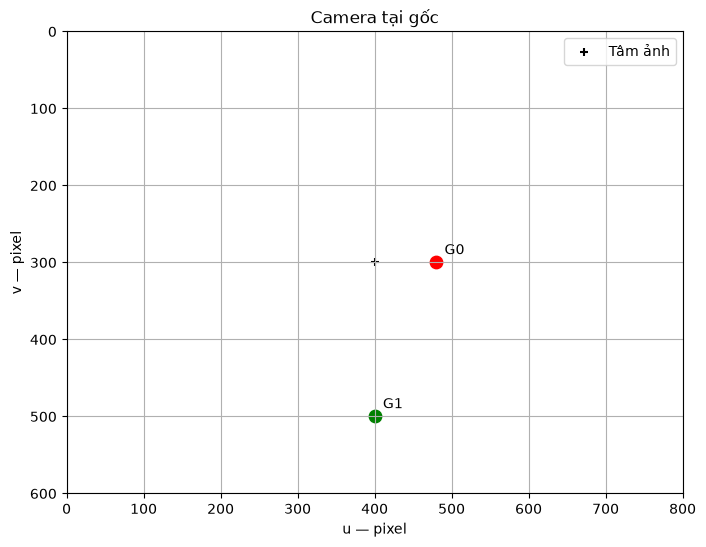

In [28]:
import matplotlib.pyplot as plt

def show_projection(pixels, valid, title):
    fig, ax = plt.subplots(figsize=(8, 6))

    for i in np.flatnonzero(valid):
        u, v = pixels[i]
        ax.scatter(u, v, color=colors[i], s=80)
        ax.annotate(f"G{i}", (u, v), xytext=(6, 6),
                    textcoords="offset points")

    ax.scatter(cx, cy, marker="+", color="black",
               label="Tâm ảnh")

    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.set_aspect("equal")
    ax.set_xlabel("u — pixel")
    ax.set_ylabel("v — pixel")
    ax.set_title(title)
    ax.grid()
    ax.legend()
    plt.show()

show_projection(pixels, valid, "Camera tại gốc")